Imports

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from random import randint

inputs = np.genfromtxt("db_thrust_yaw_input.csv", delimiter=",", dtype=np.float32)[:, :-1]
outputs = np.genfromtxt("db_thrust_yaw_output.csv", delimiter=",", dtype=np.float32)[:, :-1]

inputs.shape, outputs.shape

((5000, 644), (5000, 2898))

Stacking datasets

In [ ]:
data_names = "x y z vx vy vz ax ay az phi theta psi wx wy wz wpointx wpointy wpointz".split(' ')

In [ ]:
for i in range(18):
    print(f"Moyenne {data_names[i]} : {np.max(outputs[:, :, i])}")

Converting to thrust yaw etc

In [3]:
def drone_commands(input_array):
    M = np.array([[1,  1,  1,  1],
                  [1, -1,  1, -1],
                  [1, -1, -1,  1],
                  [1,  1, -1, -1]])
    return input_array @ M.T

In [7]:
inputs.shape, outputs.shape

((5000, 644), (5000, 2898))

Visualizing data samples

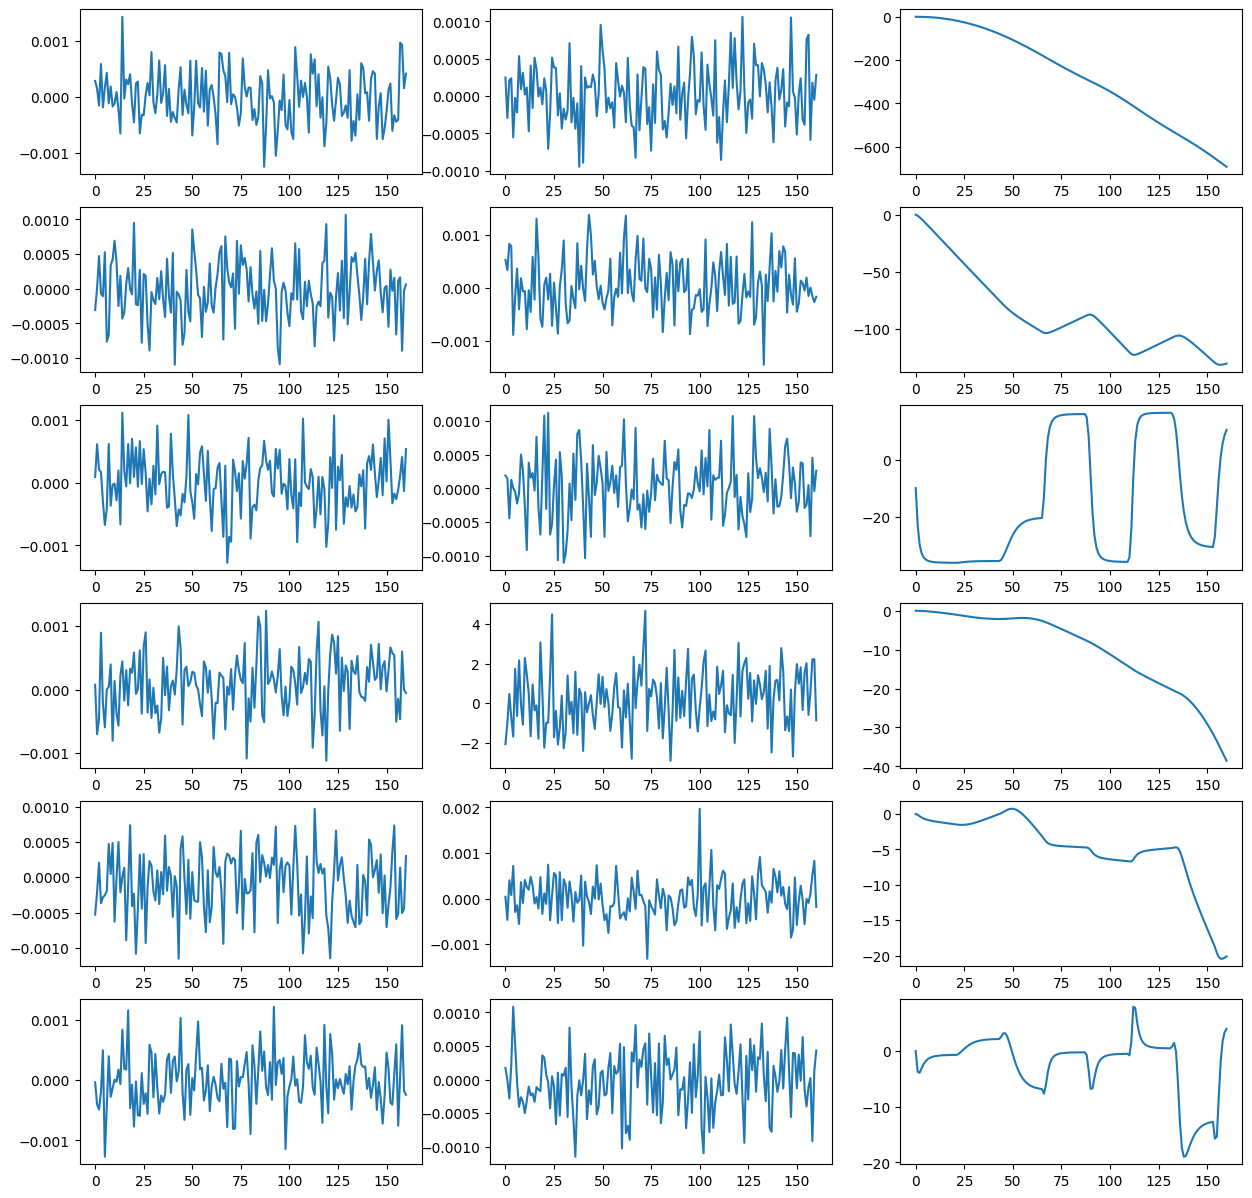

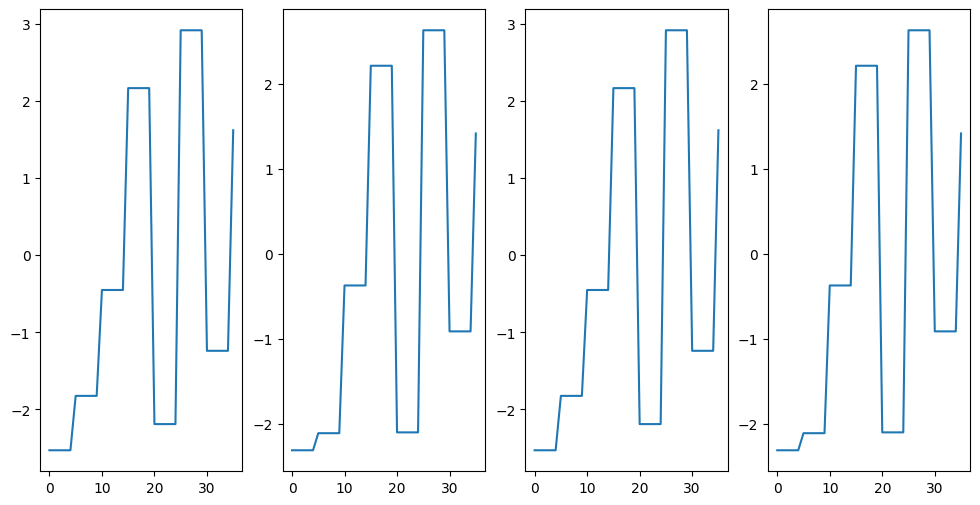

In [9]:
fig, axes = plt.subplots(len(data_names) // 3, 3)
fig.set_figheight(15)
fig.set_figwidth(15)
rand_idx = randint(0, outputs.shape[0])

for i in range(len(data_names)):
    axes[i//3, i%3].plot(outputs[rand_idx, i::18])

fig2, axes2 = plt.subplots(1, 4)
fig2.set_figheight(6)
fig2.set_figwidth(12)
for i in range(4):
    axes2[i].plot(inputs[rand_idx, i::18])

plt.show()

Deleting outliers

In [10]:
def outlier_bound(signal):
    height_limit = 30
    distance_limit = 70
    angle_limit = 70
    
    is_outlier = False
    is_outlier = is_outlier or np.max(np.abs(signal[:, 0])) > distance_limit
    is_outlier = is_outlier or np.max(np.abs(signal[:, 1])) > distance_limit
    is_outlier = is_outlier or np.max(np.abs(signal[:, 2])) > height_limit
    
    is_outlier = is_outlier or np.max(np.abs(signal[:, 9])) > angle_limit
    is_outlier = is_outlier or np.max(np.abs(signal[:, 10])) > angle_limit
    
    return is_outlier

Saving the dataset for chosen outputs

In [38]:
def save_dataset(inputs4, outputs18, 
                 save_idxs=[6, 7, 8, 15, 16, 17], 
                 outlier_function=None, 
                 inputs_name="db_inputs1.csv", outputs_name="db_outputs1.csv",
                 convert_to_commands=True):
    p_saving = np.random.permutation(inputs4.shape[0])
    inputs_permuted = inputs4[p_saving].reshape(inputs4.shape[0], -1, 4)
    outputs_permuted = outputs18[p_saving].reshape(inputs4.shape[0], -1, 2)
    
    if outlier_function is not None:
        without_outlier = np.array([signal for signal in outputs_permuted if not outlier_function(signal)])
        print(f"without outliers : {without_outlier.shape[0]}, initial total : {outputs.shape[0]}")
        input_without_outlier = np.array([val for (val, signal) in zip(inputs_permuted, outputs_permuted) if not outlier_function(signal)])
    else:
        without_outlier = outputs_permuted
        input_without_outlier = inputs_permuted
        
    if convert_to_commands:
        input_commands = drone_commands(input_without_outlier)
    else:
        input_commands = input_without_outlier
        
    input_commands = input_commands.reshape(without_outlier.shape[0], -1)
    if save_idxs is None:
        outputs_to_save = without_outlier.reshape(without_outlier.shape[0], -1)
    else:
        outputs_to_save = without_outlier[:, :, np.isin(np.arange(18) % 18, save_idxs)].reshape(without_outlier.shape[0], -1)
    
    print(input_commands.shape, outputs_to_save.shape)
    
    np.savetxt(inputs_name, input_commands, delimiter=",")
    np.savetxt(outputs_name, outputs_to_save, delimiter=",")
    

In [12]:
data_idxs = {
    "pos":[0, 1, 2, 9, 10, 11],
    "vel":[3, 4, 5, 12, 13, 14],
    "acc":[6, 7, 8, 15, 16, 17]
}

In [ ]:
save_dataset(inputs, outputs, outlier_function=None)

(5000, 644) (5000, 322)
